In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load dataset
df = pd.read_csv(
    "../dataset/sri_lanka_flood_risk_modeled.csv"
)

# Display first five records
df.head()


,date,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,district,latitude,longitude,province,climatic_zone,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score,flood_category
0,2015-01-01,1.6,1.6,0.375,0.378,29.1,8.2,Ampara,7.2912,81.6724,Eastern,Dry,1.6,1.6,1.6,0.3762,2015,0.2,Low Risk (Normal)
1,2015-01-02,1.3,1.3,0.372,0.373,28.9,7.9,Ampara,7.2912,81.6724,Eastern,Dry,1.3,2.9,2.9,0.3724,2015,0.3,Low Risk (Normal)
2,2015-01-03,0.0,0.0,0.361,0.368,29.4,11.4,Ampara,7.2912,81.6724,Eastern,Dry,0.0,1.3,2.9,0.3638,2015,0.3,Low Risk (Normal)
3,2015-01-04,0.2,0.2,0.349,0.360,29.1,13.9,Ampara,7.2912,81.6724,Eastern,Dry,0.2,0.2,1.5,0.3534,2015,0.1,Low Risk (Normal)
4,2015-01-05,3.3,3.3,0.349,0.353,27.8,16.5,Ampara,7.2912,81.6724,Eastern,Dry,3.3,3.5,3.5,0.3506,2015,0.3,Low Risk (Normal)


In [4]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (91325, 19)
<class 'pandas.DataFrame'>
RangeIndex: 91325 entries, 0 to 91324
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          91325 non-null  str    
 1   precipitation_sum             91325 non-null  float64
 2   rain_sum                      91325 non-null  float64
 3   soil_moisture_0_to_7cm_mean   91325 non-null  float64
 4   soil_moisture_7_to_28cm_mean  91325 non-null  float64
 5   temperature_2m_max            91325 non-null  float64
 6   wind_speed_10m_max            91325 non-null  float64
 7   district                      91325 non-null  str    
 8   latitude                      91325 non-null  float64
 9   longitude                     91325 non-null  float64
 10  province                      91325 non-null  str    
 11  climatic_zone                 91325 non-null  str    
 12  rain_24h                      91325 non-null

,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,latitude,longitude,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score
count,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000,91325.000000
mean,5.546671,5.546671,0.332286,0.327313,29.900777,17.156757,7.588212,80.587948,5.546671,11.089380,16.628645,0.330297,2019.500411,4.417119
std,10.224598,10.224598,0.126538,0.120991,3.253310,6.948491,1.033023,0.533065,10.224598,17.677075,24.253368,0.122669,2.872678,10.690699
min,0.000000,0.000000,0.011000,0.017000,14.700000,2.500000,5.954900,79.839400,0.000000,0.000000,0.000000,0.034400,2015.000000,0.000000
25%,0.200000,0.200000,0.233000,0.223000,28.400000,12.100000,6.927100,80.221000,0.200000,0.900000,1.800000,0.230000,2017.000000,0.200000
50%,1.800000,1.800000,0.350000,0.334000,29.800000,16.200000,7.291200,80.498200,1.800000,4.600000,7.800000,0.343200,2020.000000,0.700000
75%,6.700000,6.700000,0.443000,0.430000,31.700000,21.000000,8.311400,81.018800,6.700000,14.600000,22.500000,0.435200,2022.000000,1.900000
max,321.800000,321.800000,0.518000,0.518000,40.400000,76.000000,9.661500,81.674700,321.800000,481.500000,544.100000,0.518000,2024.000000,99.300000



Missing Values:
date                            0
precipitation_sum               0
rain_sum                        0
soil_moisture_0_to_7cm_mean     0
soil_moisture_7_to_28cm_mean    0
temperature_2m_max              0
wind_speed_10m_max              0
district                        0
latitude                        0
longitude                       0
province                        0
climatic_zone                   0
rain_24h                        0
rain_48h                        0
rain_72h                        0
soil_saturation_index           0
year                            0
flood_risk_score                0
flood_category                  0
dtype: int64

Duplicate Records: 0


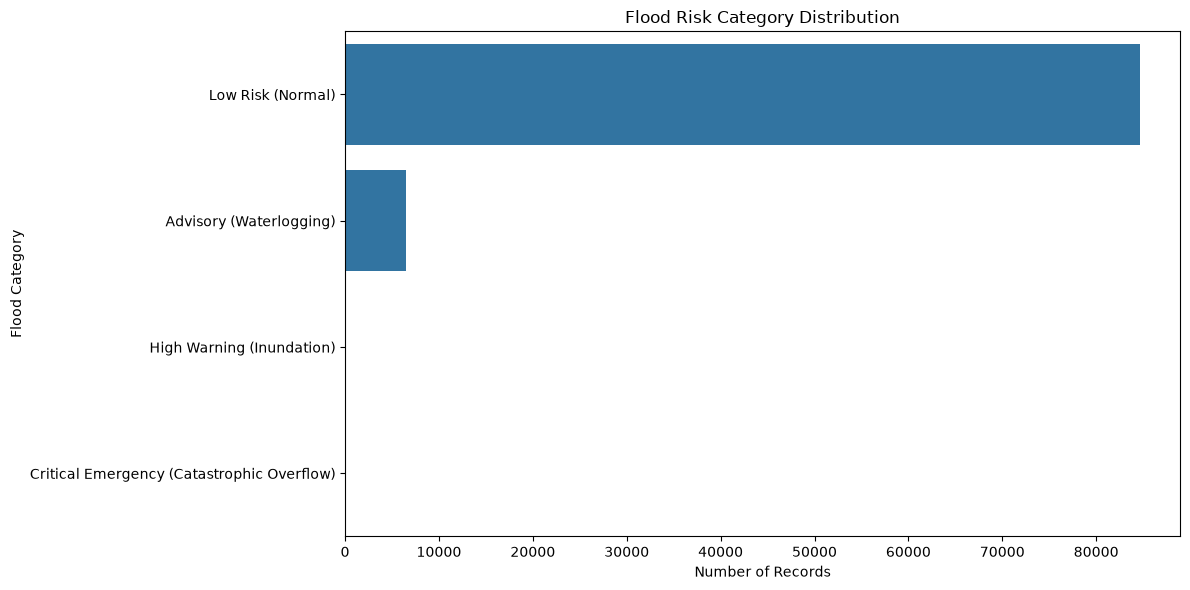

In [5]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='flood_category',
    order=df['flood_category'].value_counts().index
)

plt.title("Flood Risk Category Distribution")
plt.xlabel("Number of Records")
plt.ylabel("Flood Category")

plt.tight_layout()
plt.show()

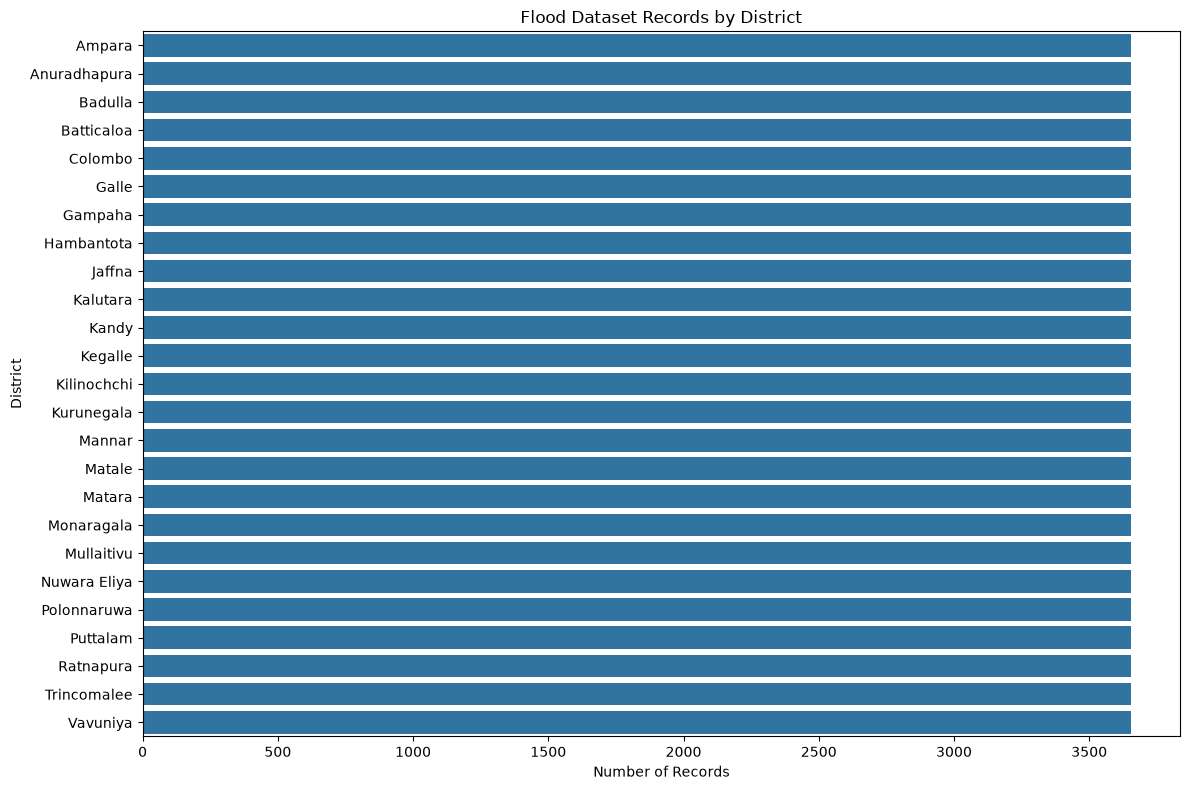

In [6]:
plt.figure(figsize=(12, 8))

district_counts = df['district'].value_counts()

sns.barplot(
    x=district_counts.values,
    y=district_counts.index
)

plt.title("Flood Dataset Records by District")
plt.xlabel("Number of Records")
plt.ylabel("District")

plt.tight_layout()
plt.show()

In [7]:
# Load dataset
df = pd.read_csv(
    "../dataset/sri_lanka_flood_risk_modeled.csv"
)

# Convert date column into datetime
df['date'] = pd.to_datetime(df['date'])

# Display dataset shape
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display first 5 records
display(df.head())

# Display dataset information
df.info()

Number of Rows: 91325
Number of Columns: 19


,date,precipitation_sum,rain_sum,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,temperature_2m_max,wind_speed_10m_max,district,latitude,longitude,province,climatic_zone,rain_24h,rain_48h,rain_72h,soil_saturation_index,year,flood_risk_score,flood_category
0,2015-01-01,1.6,1.6,0.375,0.378,29.1,8.2,Ampara,7.2912,81.6724,Eastern,Dry,1.6,1.6,1.6,0.3762,2015,0.2,Low Risk (Normal)
1,2015-01-02,1.3,1.3,0.372,0.373,28.9,7.9,Ampara,7.2912,81.6724,Eastern,Dry,1.3,2.9,2.9,0.3724,2015,0.3,Low Risk (Normal)
2,2015-01-03,0.0,0.0,0.361,0.368,29.4,11.4,Ampara,7.2912,81.6724,Eastern,Dry,0.0,1.3,2.9,0.3638,2015,0.3,Low Risk (Normal)
3,2015-01-04,0.2,0.2,0.349,0.360,29.1,13.9,Ampara,7.2912,81.6724,Eastern,Dry,0.2,0.2,1.5,0.3534,2015,0.1,Low Risk (Normal)
4,2015-01-05,3.3,3.3,0.349,0.353,27.8,16.5,Ampara,7.2912,81.6724,Eastern,Dry,3.3,3.5,3.5,0.3506,2015,0.3,Low Risk (Normal)


<class 'pandas.DataFrame'>
RangeIndex: 91325 entries, 0 to 91324
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   date                          91325 non-null  datetime64[us]
 1   precipitation_sum             91325 non-null  float64       
 2   rain_sum                      91325 non-null  float64       
 3   soil_moisture_0_to_7cm_mean   91325 non-null  float64       
 4   soil_moisture_7_to_28cm_mean  91325 non-null  float64       
 5   temperature_2m_max            91325 non-null  float64       
 6   wind_speed_10m_max            91325 non-null  float64       
 7   district                      91325 non-null  str           
 8   latitude                      91325 non-null  float64       
 9   longitude                     91325 non-null  float64       
 10  province                      91325 non-null  str           
 11  climatic_zone                 91325 non

Missing Values:
date                            0
precipitation_sum               0
rain_sum                        0
soil_moisture_0_to_7cm_mean     0
soil_moisture_7_to_28cm_mean    0
temperature_2m_max              0
wind_speed_10m_max              0
district                        0
latitude                        0
longitude                       0
province                        0
climatic_zone                   0
rain_24h                        0
rain_48h                        0
rain_72h                        0
soil_saturation_index           0
year                            0
flood_risk_score                0
flood_category                  0
dtype: int64


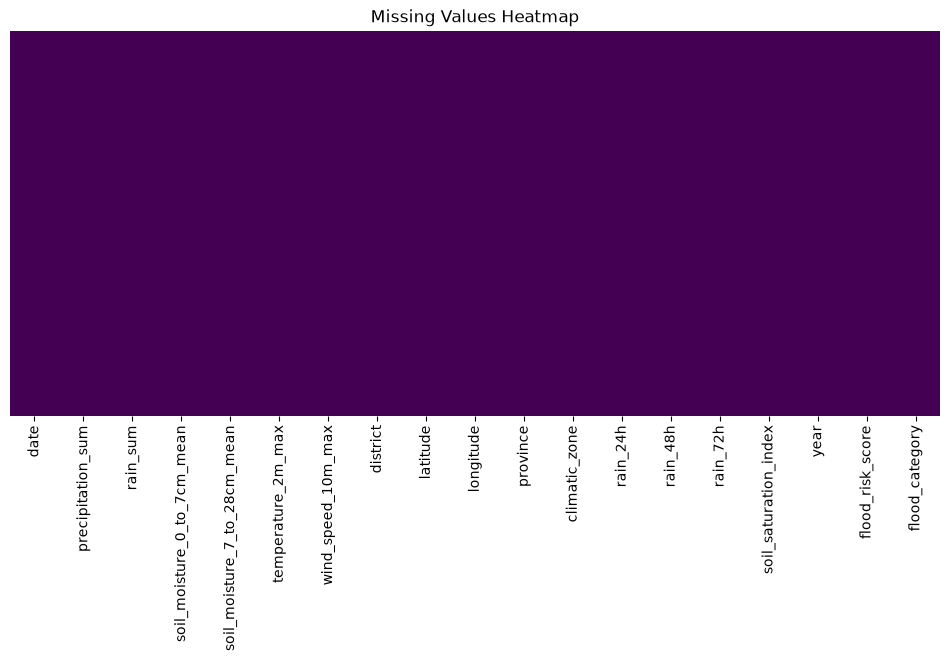

In [8]:
# Count missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Visualize missing values
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title("Missing Values Heatmap")
plt.show()

In [9]:
# Count duplicates
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

# Remove duplicates if available
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Duplicate Records: 0
Dataset Shape After Removing Duplicates: (91325, 19)


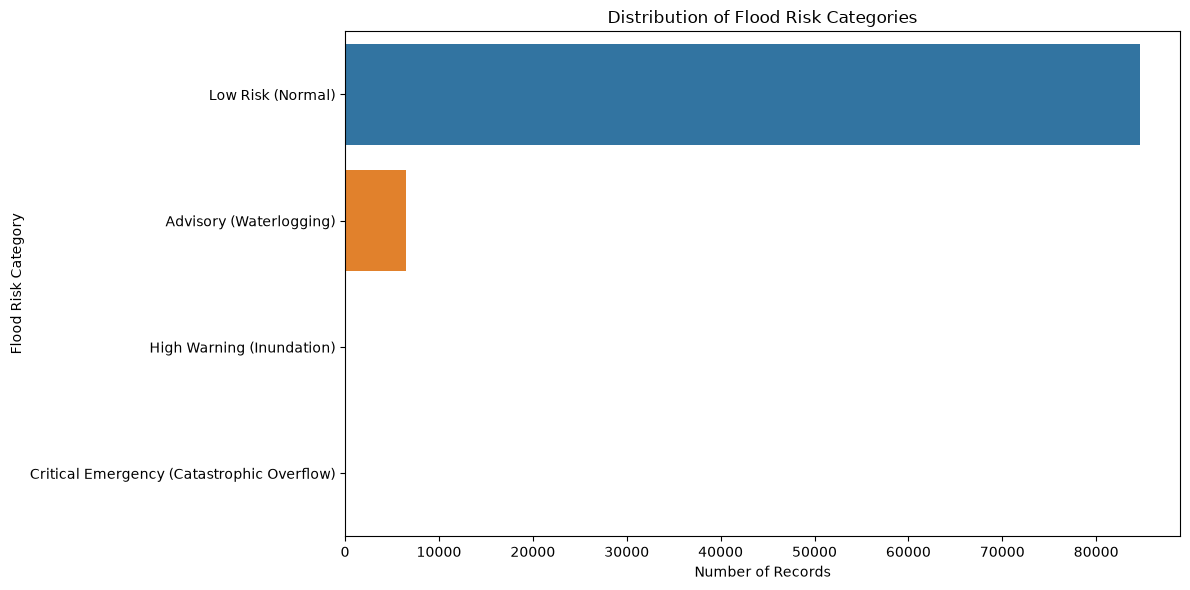

In [10]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y='flood_category',
    order=df['flood_category'].value_counts().index,
    hue='flood_category',
    legend=False
)

plt.title("Distribution of Flood Risk Categories")
plt.xlabel("Number of Records")
plt.ylabel("Flood Risk Category")

plt.tight_layout()
plt.show()

In [11]:
category_counts = df['flood_category'].value_counts()

category_percentages = (
    df['flood_category']
    .value_counts(normalize=True) * 100
)

category_summary = pd.DataFrame({
    'Count': category_counts,
    'Percentage': category_percentages.round(2)
})

display(category_summary)

,Count,Percentage
flood_category,,
Low Risk (Normal),84693,92.74
Advisory (Waterlogging),6458,7.07
High Warning (Inundation),128,0.14
Critical Emergency (Catastrophic Overflow),46,0.05


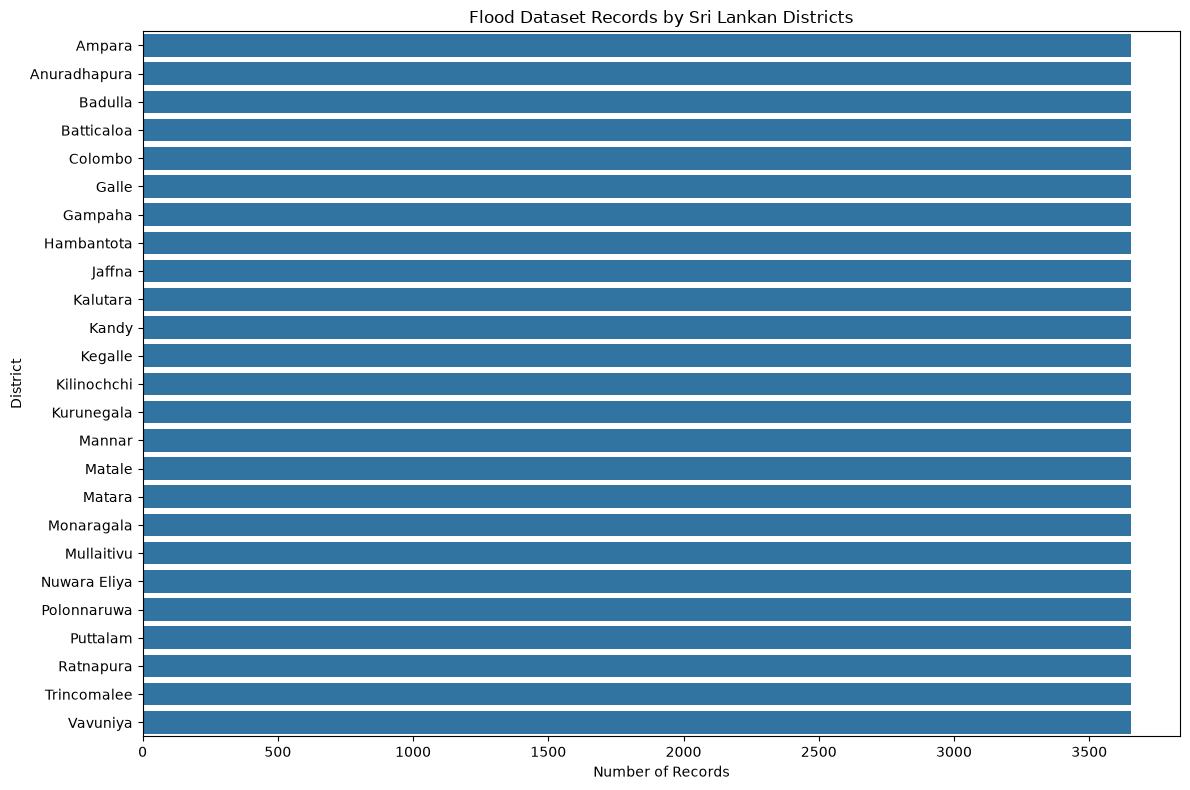

In [12]:
district_counts = (
    df.groupby('district')['flood_category']
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=district_counts.values,
    y=district_counts.index
)

plt.title("Flood Dataset Records by Sri Lankan Districts")
plt.xlabel("Number of Records")
plt.ylabel("District")

plt.tight_layout()
plt.show()

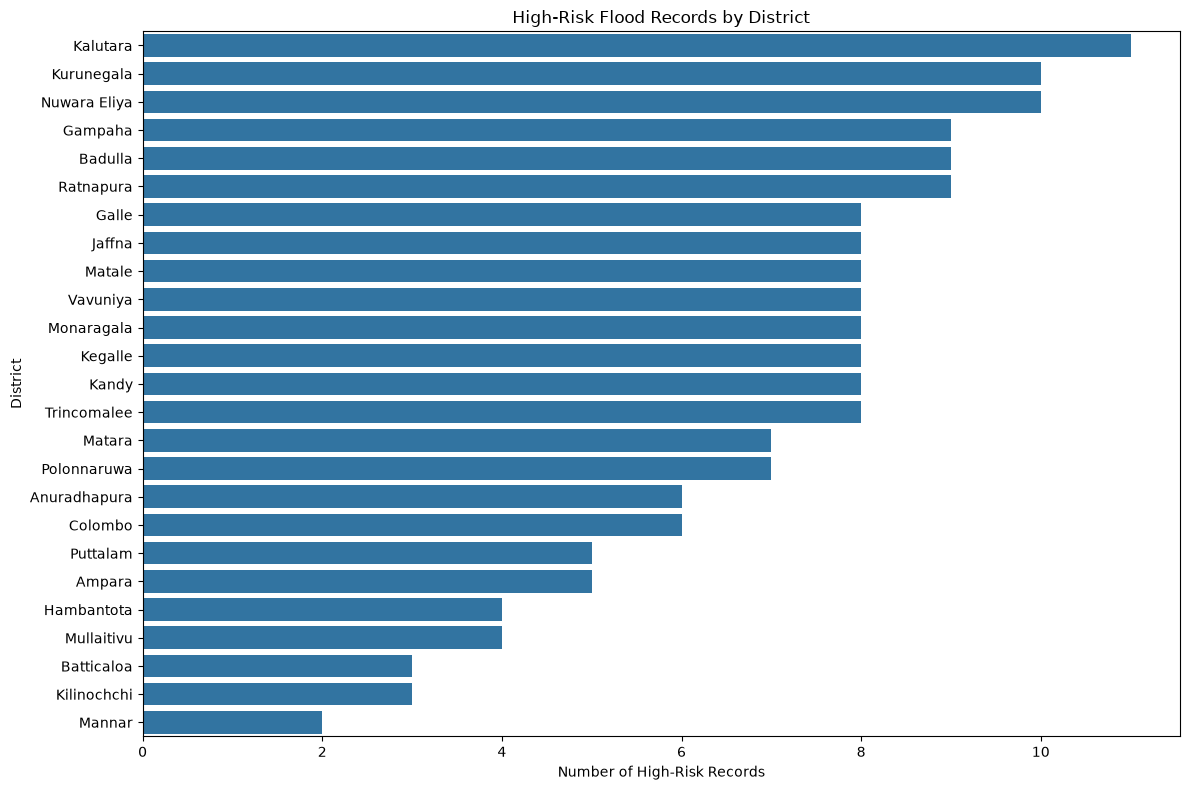

In [13]:
high_risk_categories = [
    'High Warning (Inundation)',
    'Critical Emergency (Catastrophic Overflow)'
]

high_risk_df = df[
    df['flood_category'].isin(high_risk_categories)
]

district_risk = (
    high_risk_df.groupby('district')
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=district_risk.values,
    y=district_risk.index
)

plt.title("High-Risk Flood Records by District")
plt.xlabel("Number of High-Risk Records")
plt.ylabel("District")

plt.tight_layout()
plt.show()

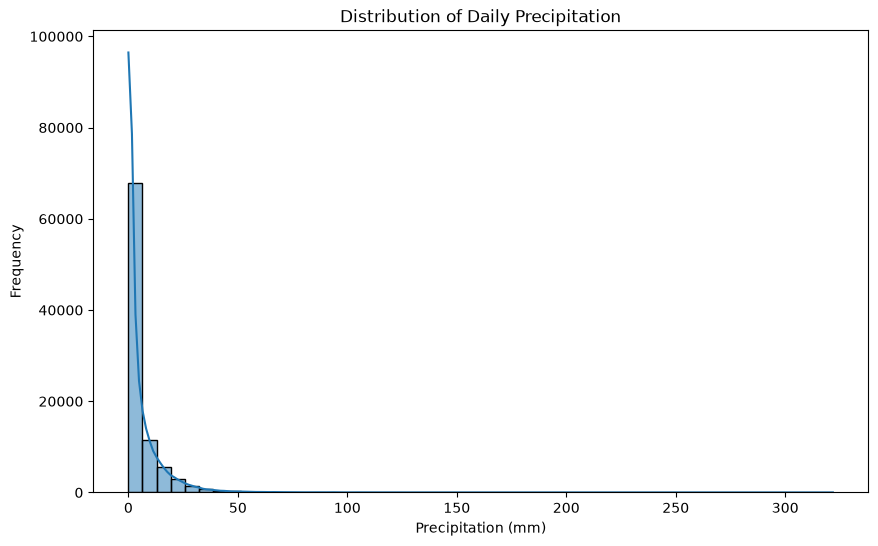

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='precipitation_sum',
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Precipitation")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")

plt.show()

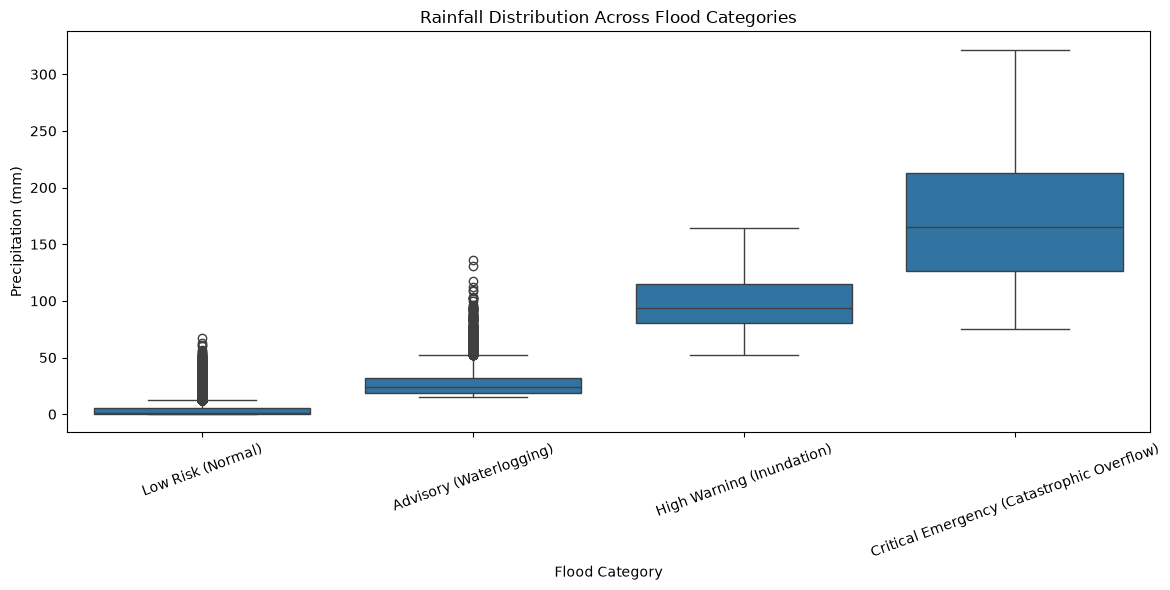

In [18]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='flood_category',
    y='precipitation_sum'
)

plt.title("Rainfall Distribution Across Flood Categories")
plt.xlabel("Flood Category")
plt.ylabel("Precipitation (mm)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [19]:
rainfall_analysis = (
    df.groupby('flood_category')[
        ['precipitation_sum', 'rain_48h', 'rain_72h']
    ].mean()
)

display(rainfall_analysis)

,precipitation_sum,rain_48h,rain_72h
flood_category,,,
Advisory (Waterlogging),27.831449,47.902276,64.234206
Critical Emergency (Catastrophic Overflow),171.504348,249.176087,275.089130
High Warning (Inundation),98.531250,142.300781,170.021875
Low Risk (Normal),3.616745,7.954708,12.626422


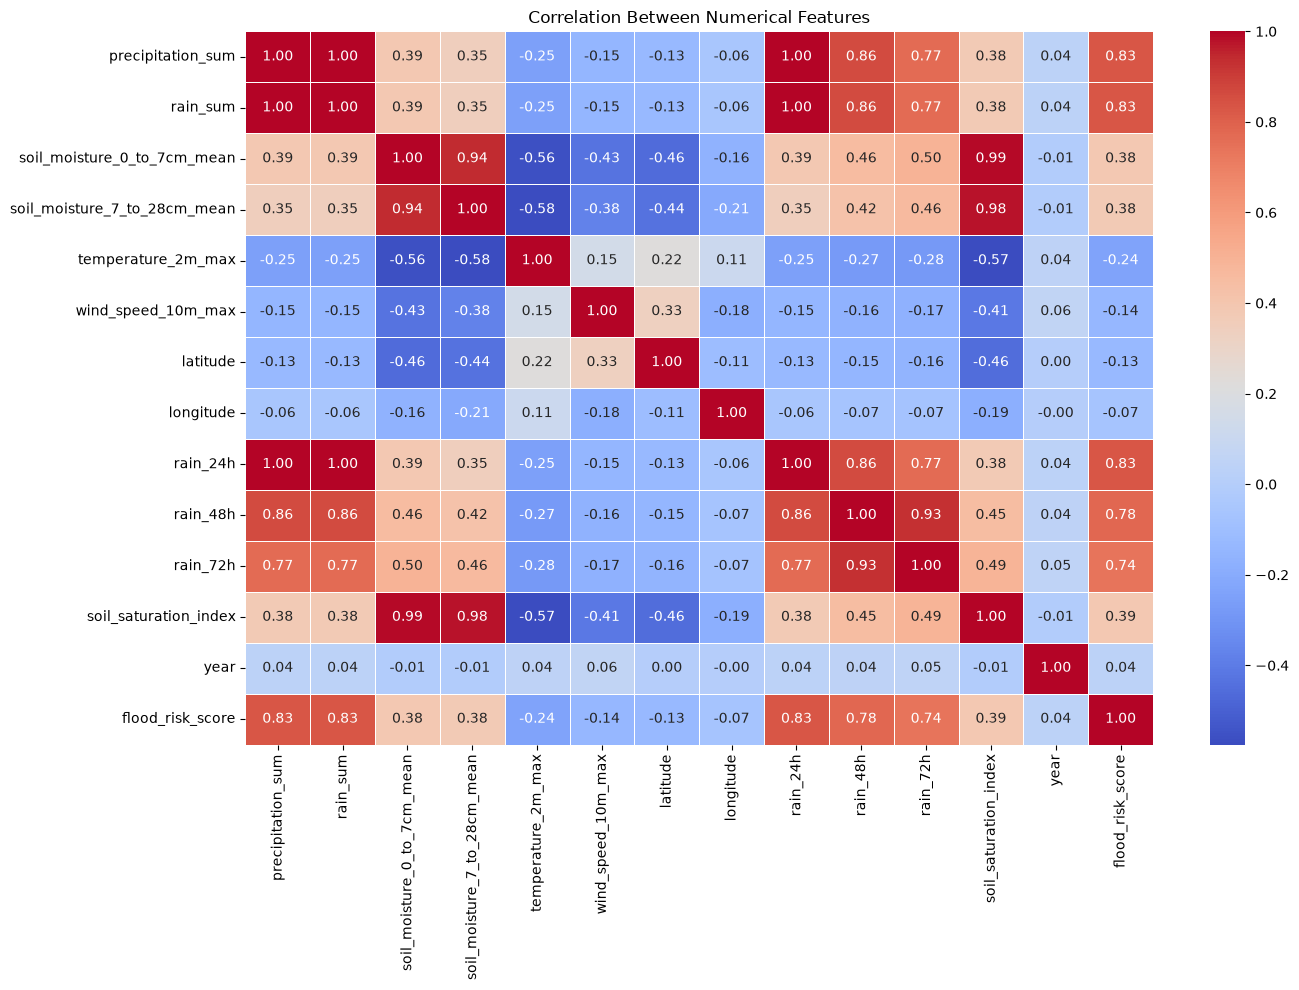

In [20]:
numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

correlation_matrix = numerical_df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")

plt.tight_layout()
plt.show()

In [21]:
# Create a copy of the dataset
df_model = df.copy()

# Extract month
df_model['month'] = df_model['date'].dt.month

# Extract day of year
df_model['day_of_year'] = df_model['date'].dt.dayofyear

# Extract year
df_model['year'] = df_model['date'].dt.year

# Display new features
display(
    df_model[
        ['date', 'month', 'day_of_year', 'year']
    ].head()
)

,date,month,day_of_year,year
0,2015-01-01,1,1,2015
1,2015-01-02,1,2,2015
2,2015-01-03,1,3,2015
3,2015-01-04,1,4,2015
4,2015-01-05,1,5,2015


In [22]:
# Columns that will not be used as input features
columns_to_drop = [
    'date',
    'rain_sum',
    'rain_24h',
    'flood_risk_score'
]

df_model = df_model.drop(
    columns=columns_to_drop
)

print("Remaining Columns:")
print(df_model.columns.tolist())

print("\nDataset Shape:", df_model.shape)

Remaining Columns:
['precipitation_sum', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'temperature_2m_max', 'wind_speed_10m_max', 'district', 'latitude', 'longitude', 'province', 'climatic_zone', 'rain_48h', 'rain_72h', 'soil_saturation_index', 'year', 'flood_category', 'month', 'day_of_year']

Dataset Shape: (91325, 17)


In [23]:
# Define target variable
target = 'flood_category'

# Separate input features and target
X = df_model.drop(columns=[target])

y = df_model[target]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Categories:")
print(y.unique())

Feature Shape: (91325, 16)
Target Shape: (91325,)

Input Features:
['precipitation_sum', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'temperature_2m_max', 'wind_speed_10m_max', 'district', 'latitude', 'longitude', 'province', 'climatic_zone', 'rain_48h', 'rain_72h', 'soil_saturation_index', 'year', 'month', 'day_of_year']

Target Categories:
<ArrowStringArray>
[                         'Low Risk (Normal)',
                    'Advisory (Waterlogging)',
                  'High Warning (Inundation)',
 'Critical Emergency (Catastrophic Overflow)']
Length: 4, dtype: str


In [24]:
# Use original dates to create chronological split
split_date = pd.Timestamp('2022-12-31')

train_indices = df['date'] <= split_date
test_indices = df['date'] > split_date

# Training data
X_train = X.loc[train_indices].copy()
y_train = y.loc[train_indices].copy()

# Testing data
X_test = X.loc[test_indices].copy()
y_test = y.loc[test_indices].copy()

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Date Range:",
      df.loc[train_indices, 'date'].min(),
      "to",
      df.loc[train_indices, 'date'].max())

print("Testing Date Range:",
      df.loc[test_indices, 'date'].min(),
      "to",
      df.loc[test_indices, 'date'].max())

Training Data: (73050, 16)
Testing Data: (18275, 16)
Training Date Range: 2015-01-01 00:00:00 to 2022-12-31 00:00:00
Testing Date Range: 2023-01-01 00:00:00 to 2024-12-31 00:00:00


In [25]:
print("TRAINING CATEGORY DISTRIBUTION")
print(y_train.value_counts())

print("\nTESTING CATEGORY DISTRIBUTION")
print(y_test.value_counts())

TRAINING CATEGORY DISTRIBUTION
flood_category
Low Risk (Normal)                             68001
Advisory (Waterlogging)                        4904
High Warning (Inundation)                       105
Critical Emergency (Catastrophic Overflow)       40
Name: count, dtype: int64

TESTING CATEGORY DISTRIBUTION
flood_category
Low Risk (Normal)                             16692
Advisory (Waterlogging)                        1554
High Warning (Inundation)                        23
Critical Emergency (Catastrophic Overflow)        6
Name: count, dtype: int64


## 3. Machine Learning Model Development

### 3.1 Data Preprocessing for Machine Learning

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

import time

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [27]:
# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

# Identify numerical columns
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['district', 'province', 'climatic_zone']

Numerical Features:
['precipitation_sum', 'soil_moisture_0_to_7cm_mean', 'soil_moisture_7_to_28cm_mean', 'temperature_2m_max', 'wind_speed_10m_max', 'latitude', 'longitude', 'rain_48h', 'rain_72h', 'soil_saturation_index']


In [28]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [29]:
# Fit preprocessing using training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (73050, 47)
Testing Data Shape: (18275, 47)


In [30]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

# Train model
start_time = time.time()

dt_model.fit(X_train_processed, y_train)

dt_training_time = time.time() - start_time

print("Decision Tree training completed!")
print("Training Time:", round(dt_training_time, 2), "seconds")

Decision Tree training completed!
Training Time: 0.49 seconds


In [31]:
# Predict using Decision Tree
dt_predictions = dt_model.predict(X_test_processed)

print("Decision Tree Predictions:")
print(dt_predictions[:20])

Decision Tree Predictions:
['Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)']


In [32]:
print("DECISION TREE CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        dt_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      accuracy_score(y_test, dt_predictions))

print("Macro F1:",
      f1_score(y_test, dt_predictions, average='macro'))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, dt_predictions))

DECISION TREE CLASSIFICATION REPORT
                                            precision    recall  f1-score   support

                   Advisory (Waterlogging)       0.94      0.98      0.96      1554
Critical Emergency (Catastrophic Overflow)       0.36      0.67      0.47         6
                 High Warning (Inundation)       0.55      0.74      0.63        23
                         Low Risk (Normal)       1.00      0.99      1.00     16692

                                  accuracy                           0.99     18275
                                 macro avg       0.71      0.85      0.76     18275
                              weighted avg       0.99      0.99      0.99     18275

Accuracy: 0.9930506155950752
Macro F1: 0.7647223405666279
Balanced Accuracy: 0.8451441487300894


In [33]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created!")

Random Forest model created!


In [34]:
start_time = time.time()

rf_model.fit(X_train_processed, y_train)

rf_training_time = time.time() - start_time

print("Random Forest training completed!")

print(
    "Training Time:",
    round(rf_training_time, 2),
    "seconds"
)

Random Forest training completed!
Training Time: 7.62 seconds


In [35]:
rf_predictions = rf_model.predict(X_test_processed)

print("Random Forest Predictions:")
print(rf_predictions[:20])

Random Forest Predictions:
['Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)']


In [36]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      accuracy_score(y_test, rf_predictions))

print("Macro F1:",
      f1_score(y_test, rf_predictions, average='macro'))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, rf_predictions))

RANDOM FOREST CLASSIFICATION REPORT
                                            precision    recall  f1-score   support

                   Advisory (Waterlogging)       0.97      0.98      0.97      1554
Critical Emergency (Catastrophic Overflow)       0.50      0.83      0.62         6
                 High Warning (Inundation)       0.62      0.65      0.64        23
                         Low Risk (Normal)       1.00      1.00      1.00     16692

                                  accuracy                           1.00     18275
                                 macro avg       0.77      0.87      0.81     18275
                              weighted avg       1.00      1.00      1.00     18275

Accuracy: 0.9952941176470588
Macro F1: 0.8089296911944095
Balanced Accuracy: 0.8664302184466752


In [37]:
et_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("Extra Trees model created!")

Extra Trees model created!


In [39]:
start_time = time.time()

et_model.fit(X_train_processed, y_train)

et_training_time = time.time() - start_time

print("Extra Trees training completed!")

print(
    "Training Time:",
    round(et_training_time, 2),
    "seconds"
)

Extra Trees training completed!
Training Time: 10.72 seconds


In [40]:
et_predictions = et_model.predict(X_test_processed)

print("Extra Trees Predictions:")
print(et_predictions[:20])

Extra Trees Predictions:
['Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)']


In [41]:
print("EXTRA TREES CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        et_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      accuracy_score(y_test, et_predictions))

print("Macro F1:",
      f1_score(y_test, et_predictions, average='macro'))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, et_predictions))

EXTRA TREES CLASSIFICATION REPORT
                                            precision    recall  f1-score   support

                   Advisory (Waterlogging)       0.65      0.98      0.79      1554
Critical Emergency (Catastrophic Overflow)       0.40      0.67      0.50         6
                 High Warning (Inundation)       0.46      0.70      0.55        23
                         Low Risk (Normal)       1.00      0.95      0.98     16692

                                  accuracy                           0.95     18275
                                 macro avg       0.63      0.82      0.70     18275
                              weighted avg       0.97      0.95      0.96     18275

Accuracy: 0.9541450068399453
Macro F1: 0.7033164022576156
Balanced Accuracy: 0.8246620324281844


In [42]:
models = {
    'Decision Tree': (dt_model, dt_predictions, dt_training_time),
    'Random Forest': (rf_model, rf_predictions, rf_training_time),
    'Extra Trees': (et_model, et_predictions, et_training_time)
}

results = []

for name, (model, predictions, training_time) in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),
        'Macro F1': f1_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),
        'Balanced Accuracy': balanced_accuracy_score(
            y_test, predictions
        ),
        'Training Time (s)': training_time
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        by='Macro F1',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,Macro F1,Balanced Accuracy,Training Time (s)
1,Random Forest,0.9953,0.7724,0.8664,0.8089,0.8664,7.6208
0,Decision Tree,0.9931,0.7138,0.8451,0.7647,0.8451,0.4917
2,Extra Trees,0.9541,0.6279,0.8247,0.7033,0.8247,10.7244


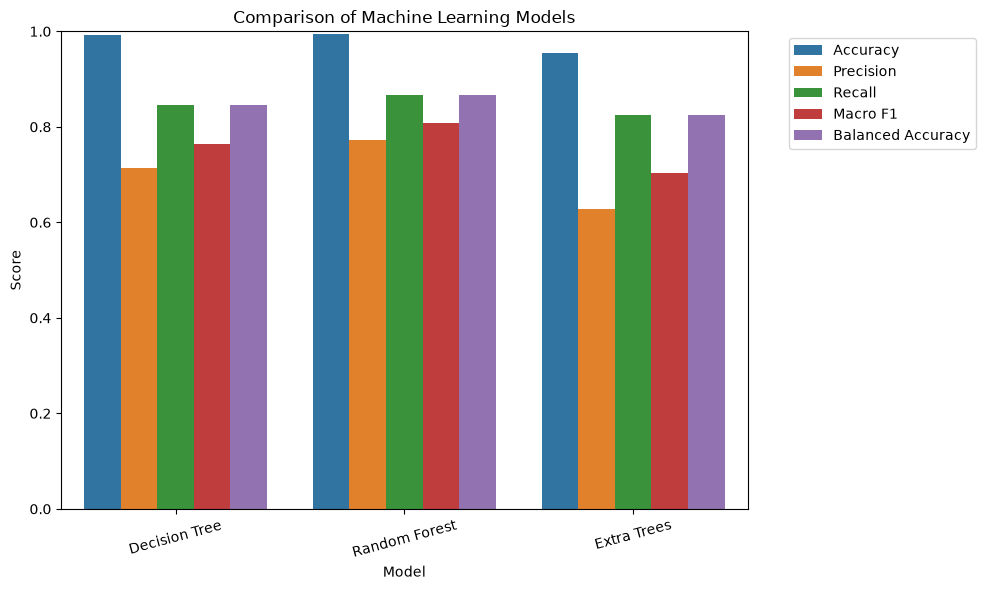

In [43]:
plt.figure(figsize=(10, 6))

comparison_plot = comparison_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy',
        'Precision',
        'Recall',
        'Macro F1',
        'Balanced Accuracy'
    ],
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=comparison_plot,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Comparison of Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 3.8 XGBoost Model Implementation

In [44]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

print("XGBoost imported successfully!")

XGBoost imported successfully!


In [45]:
# Create label encoder
label_encoder = LabelEncoder()

# Encode target labels
y_train_encoded = label_encoder.fit_transform(y_train)

y_test_encoded = label_encoder.transform(y_test)

# Display mapping
class_mapping = dict(
    zip(label_encoder.classes_,
        label_encoder.transform(label_encoder.classes_))
)

print("Class Mapping:")
print(class_mapping)

Class Mapping:
{'Advisory (Waterlogging)': np.int64(0), 'Critical Emergency (Catastrophic Overflow)': np.int64(1), 'High Warning (Inundation)': np.int64(2), 'Low Risk (Normal)': np.int64(3)}


In [46]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(label_encoder.classes_),
    eval_metric='mlogloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully!")

XGBoost model created successfully!


In [47]:
# Calculate balanced sample weights
xgb_sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_encoded
)

# Train XGBoost
start_time = time.time()

xgb_model.fit(
    X_train_processed,
    y_train_encoded,
    sample_weight=xgb_sample_weights
)

xgb_training_time = time.time() - start_time

print("XGBoost training completed!")

print(
    "Training Time:",
    round(xgb_training_time, 2),
    "seconds"
)

XGBoost training completed!
Training Time: 3.39 seconds


In [48]:
# Predict encoded labels
xgb_predictions_encoded = xgb_model.predict(
    X_test_processed
)

# Convert predictions back to original category names
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded
)

print("XGBoost Predictions:")
print(xgb_predictions[:20])

XGBoost Predictions:
['Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)']


In [49]:
print("XGBOOST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        xgb_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      accuracy_score(y_test, xgb_predictions))

print("Macro F1:",
      f1_score(
          y_test,
          xgb_predictions,
          average='macro',
          zero_division=0
      ))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, xgb_predictions))

XGBOOST CLASSIFICATION REPORT
                                            precision    recall  f1-score   support

                   Advisory (Waterlogging)       0.94      0.99      0.96      1554
Critical Emergency (Catastrophic Overflow)       0.67      0.67      0.67         6
                 High Warning (Inundation)       0.62      0.87      0.73        23
                         Low Risk (Normal)       1.00      0.99      1.00     16692

                                  accuracy                           0.99     18275
                                 macro avg       0.81      0.88      0.84     18275
                              weighted avg       0.99      0.99      0.99     18275

Accuracy: 0.9931600547195623
Macro F1: 0.8382084042039548
Balanced Accuracy: 0.8802181318942798


### 3.9 Stacking Classifier Implementation

In [50]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

print("Stacking libraries imported successfully!")

Stacking libraries imported successfully!


In [51]:
# Base Model 1: Random Forest
stack_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# Base Model 2: Extra Trees
stack_et = ExtraTreesClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Base Model 3: XGBoost
stack_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(label_encoder.classes_),
    eval_metric='mlogloss',
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

print("Three base estimators created!")

Three base estimators created!


In [52]:
meta_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

print("Meta-model created successfully!")

Meta-model created successfully!


In [53]:
# Define cross-validation
stack_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create stacking classifier
stacking_model = StackingClassifier(
    estimators=[
        ('random_forest', stack_rf),
        ('extra_trees', stack_et),
        ('xgboost', stack_xgb)
    ],
    final_estimator=meta_model,
    cv=stack_cv,
    stack_method='predict_proba',
    passthrough=False,
    n_jobs=1
)

print("Stacking Classifier created successfully!")

Stacking Classifier created successfully!


In [54]:
start_time = time.time()

stacking_model.fit(
    X_train_processed,
    y_train_encoded
)

stacking_training_time = time.time() - start_time

print("Stacking Classifier training completed!")

print(
    "Training Time:",
    round(stacking_training_time, 2),
    "seconds"
)

Stacking Classifier training completed!
Training Time: 31.81 seconds


In [55]:
# Predict using stacking model
stack_predictions_encoded = stacking_model.predict(
    X_test_processed
)

# Convert encoded predictions to original labels
stack_predictions = label_encoder.inverse_transform(
    stack_predictions_encoded
)

print("Stacking Predictions:")
print(stack_predictions[:20])

Stacking Predictions:
['Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)' 'Low Risk (Normal)'
 'Low Risk (Normal)' 'Low Risk (Normal)']


In [56]:
print("STACKING CLASSIFIER REPORT")

print(
    classification_report(
        y_test,
        stack_predictions,
        zero_division=0
    )
)

print("Accuracy:",
      accuracy_score(y_test, stack_predictions))

print("Macro F1:",
      f1_score(
          y_test,
          stack_predictions,
          average='macro',
          zero_division=0
      ))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, stack_predictions))

STACKING CLASSIFIER REPORT
                                            precision    recall  f1-score   support

                   Advisory (Waterlogging)       0.95      0.98      0.96      1554
Critical Emergency (Catastrophic Overflow)       0.45      0.83      0.59         6
                 High Warning (Inundation)       0.37      0.74      0.49        23
                         Low Risk (Normal)       1.00      1.00      1.00     16692

                                  accuracy                           0.99     18275
                                 macro avg       0.69      0.89      0.76     18275
                              weighted avg       0.99      0.99      0.99     18275

Accuracy: 0.9934336525307798
Macro F1: 0.7606552224071039
Balanced Accuracy: 0.886608882951833


In [57]:
all_models = {
    'Decision Tree': (
        dt_predictions, dt_training_time
    ),
    'Random Forest': (
        rf_predictions, rf_training_time
    ),
    'Extra Trees': (
        et_predictions, et_training_time
    ),
    'XGBoost': (
        xgb_predictions, xgb_training_time
    ),
    'Stacking Classifier': (
        stack_predictions, stacking_training_time
    )
}

final_results = []

for name, (predictions, training_time) in all_models.items():

    final_results.append({
        'Model': name,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Precision': precision_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),

        'Recall': recall_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),

        'Macro F1': f1_score(
            y_test, predictions,
            average='macro',
            zero_division=0
        ),

        'Balanced Accuracy': balanced_accuracy_score(
            y_test, predictions
        ),

        'Training Time (s)': training_time
    })

final_comparison_df = pd.DataFrame(final_results)

final_comparison_df = final_comparison_df.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

display(final_comparison_df.round(4))

,Model,Accuracy,Precision,Recall,Macro F1,Balanced Accuracy,Training Time (s)
0,XGBoost,0.9932,0.8066,0.8802,0.8382,0.8802,3.3935
1,Random Forest,0.9953,0.7724,0.8664,0.8089,0.8664,7.6208
2,Decision Tree,0.9931,0.7138,0.8451,0.7647,0.8451,0.4917
3,Stacking Classifier,0.9934,0.6935,0.8866,0.7607,0.8866,31.8121
4,Extra Trees,0.9541,0.6279,0.8247,0.7033,0.8247,10.7244


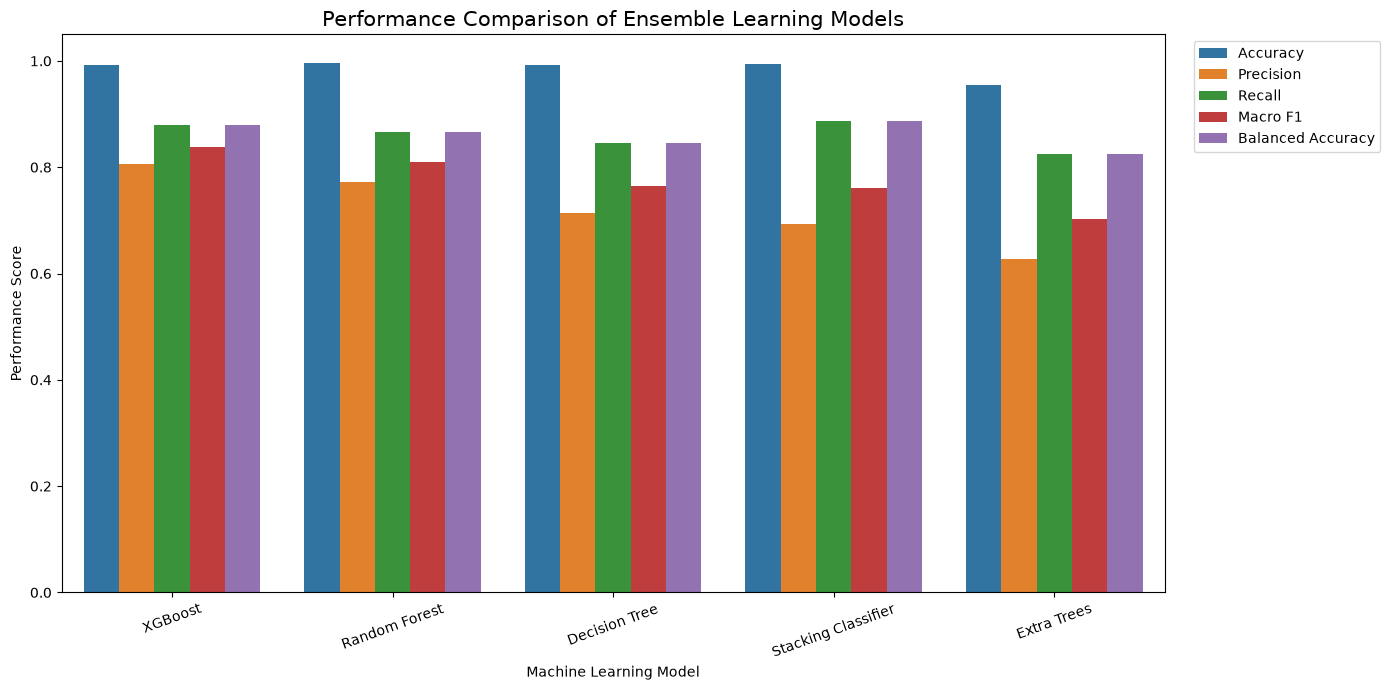

In [58]:
plt.figure(figsize=(14, 7))

plot_data = final_comparison_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy',
        'Precision',
        'Recall',
        'Macro F1',
        'Balanced Accuracy'
    ],
    var_name='Metric',
    value_name='Score'
)

sns.barplot(
    data=plot_data,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title(
    'Performance Comparison of Ensemble Learning Models',
    fontsize=15
)

plt.ylabel('Performance Score')
plt.xlabel('Machine Learning Model')

plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [59]:
best_model_row = final_comparison_df.iloc[0]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model_row['Model'])

print(
    "Accuracy:",
    round(best_model_row['Accuracy'], 4)
)

print(
    "Macro F1:",
    round(best_model_row['Macro F1'], 4)
)

print(
    "Balanced Accuracy:",
    round(best_model_row['Balanced Accuracy'], 4)
)

BEST PERFORMING MODEL
---------------------
Model: XGBoost
Accuracy: 0.9932
Macro F1: 0.8382
Balanced Accuracy: 0.8802


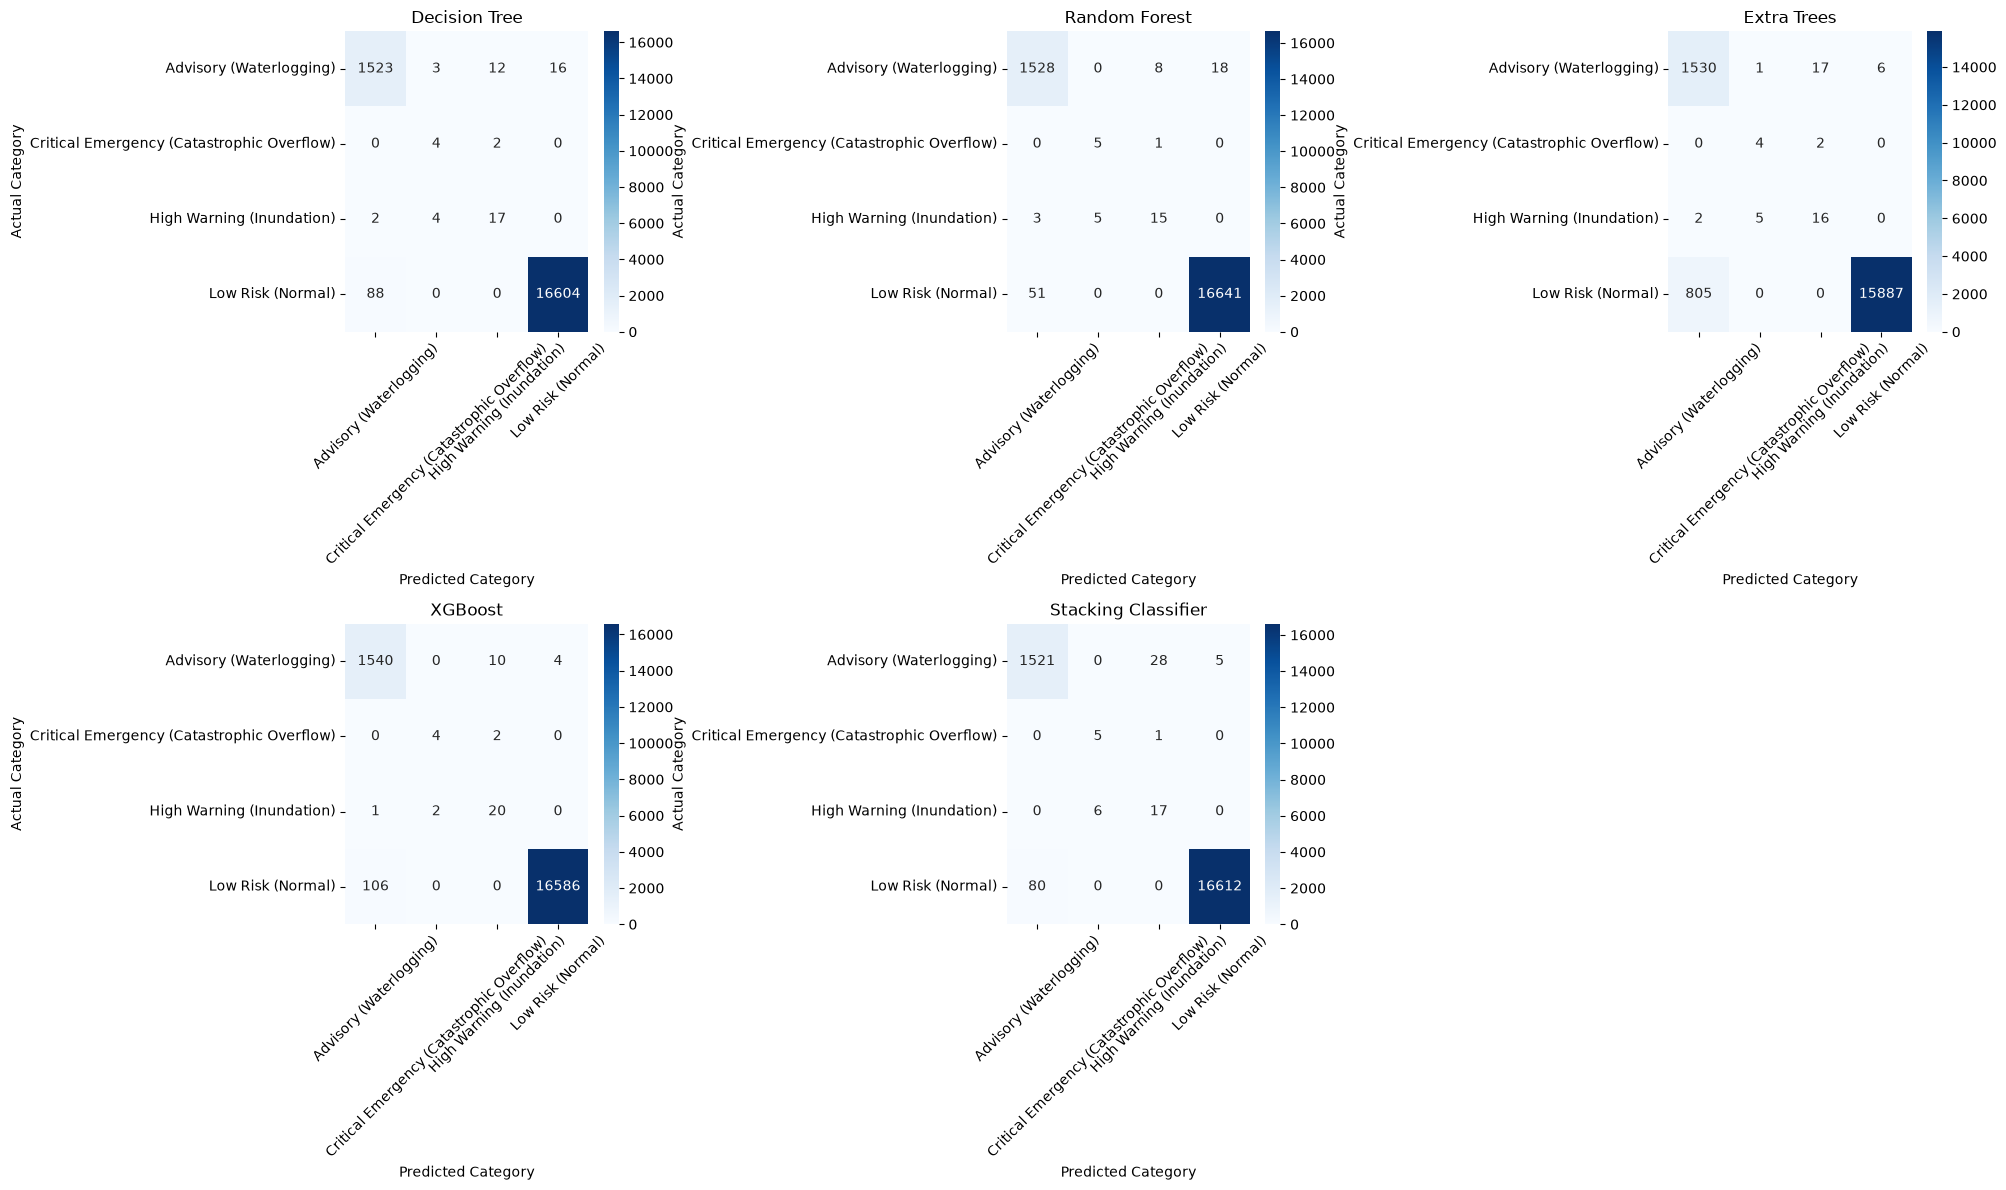

In [60]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 12)
)

axes = axes.flatten()

for i, (name, (predictions, _)) in enumerate(all_models.items()):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=label_encoder.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted Category')
    axes[i].set_ylabel('Actual Category')

    axes[i].tick_params(axis='x', rotation=45)
    axes[i].tick_params(axis='y', rotation=0)

# Hide unused subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

In [61]:
import os
import joblib

# Create models directory
os.makedirs('../models', exist_ok=True)

# Save preprocessing object
joblib.dump(
    preprocessor,
    '../models/preprocessor.pkl'
)

# Save label encoder
joblib.dump(
    label_encoder,
    '../models/label_encoder.pkl'
)

# Save models
joblib.dump(
    dt_model,
    '../models/decision_tree.pkl'
)

joblib.dump(
    rf_model,
    '../models/random_forest.pkl'
)

joblib.dump(
    et_model,
    '../models/extra_trees.pkl'
)

joblib.dump(
    xgb_model,
    '../models/xgboost.pkl'
)

joblib.dump(
    stacking_model,
    '../models/stacking_model.pkl'
)

# Save comparison results
final_comparison_df.to_csv(
    '../models/model_comparison.csv',
    index=False
)

print("All models and preprocessing objects saved successfully!")

All models and preprocessing objects saved successfully!


In [65]:
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFeature Names:")
print(feature_names)

Total Features: 47

Feature Names:
['num__precipitation_sum' 'num__soil_moisture_0_to_7cm_mean'
 'num__soil_moisture_7_to_28cm_mean' 'num__temperature_2m_max'
 'num__wind_speed_10m_max' 'num__latitude' 'num__longitude'
 'num__rain_48h' 'num__rain_72h' 'num__soil_saturation_index'
 'cat__district_Ampara' 'cat__district_Anuradhapura'
 'cat__district_Badulla' 'cat__district_Batticaloa'
 'cat__district_Colombo' 'cat__district_Galle' 'cat__district_Gampaha'
 'cat__district_Hambantota' 'cat__district_Jaffna'
 'cat__district_Kalutara' 'cat__district_Kandy' 'cat__district_Kegalle'
 'cat__district_Kilinochchi' 'cat__district_Kurunegala'
 'cat__district_Mannar' 'cat__district_Matale' 'cat__district_Matara'
 'cat__district_Monaragala' 'cat__district_Mullaitivu'
 'cat__district_Nuwara Eliya' 'cat__district_Polonnaruwa'
 'cat__district_Puttalam' 'cat__district_Ratnapura'
 'cat__district_Trincomalee' 'cat__district_Vavuniya'
 'cat__province_Central' 'cat__province_Eastern'
 'cat__province_North Cent

In [66]:
# Extract feature importance
rf_importance = rf_model.feature_importances_

# Create dataframe
rf_feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_importance
})

# Sort by importance
rf_feature_importance = rf_feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(rf_feature_importance.head(20))

,Feature,Importance
0,num__precipitation_sum,0.291617
7,num__rain_48h,0.225457
8,num__rain_72h,0.171909
9,num__soil_saturation_index,0.058941
1,num__soil_moisture_0_to_7cm_mean,0.056304
2,num__soil_moisture_7_to_28cm_mean,0.049760
3,num__temperature_2m_max,0.045340
4,num__wind_speed_10m_max,0.026663
5,num__latitude,0.012876
6,num__longitude,0.010632


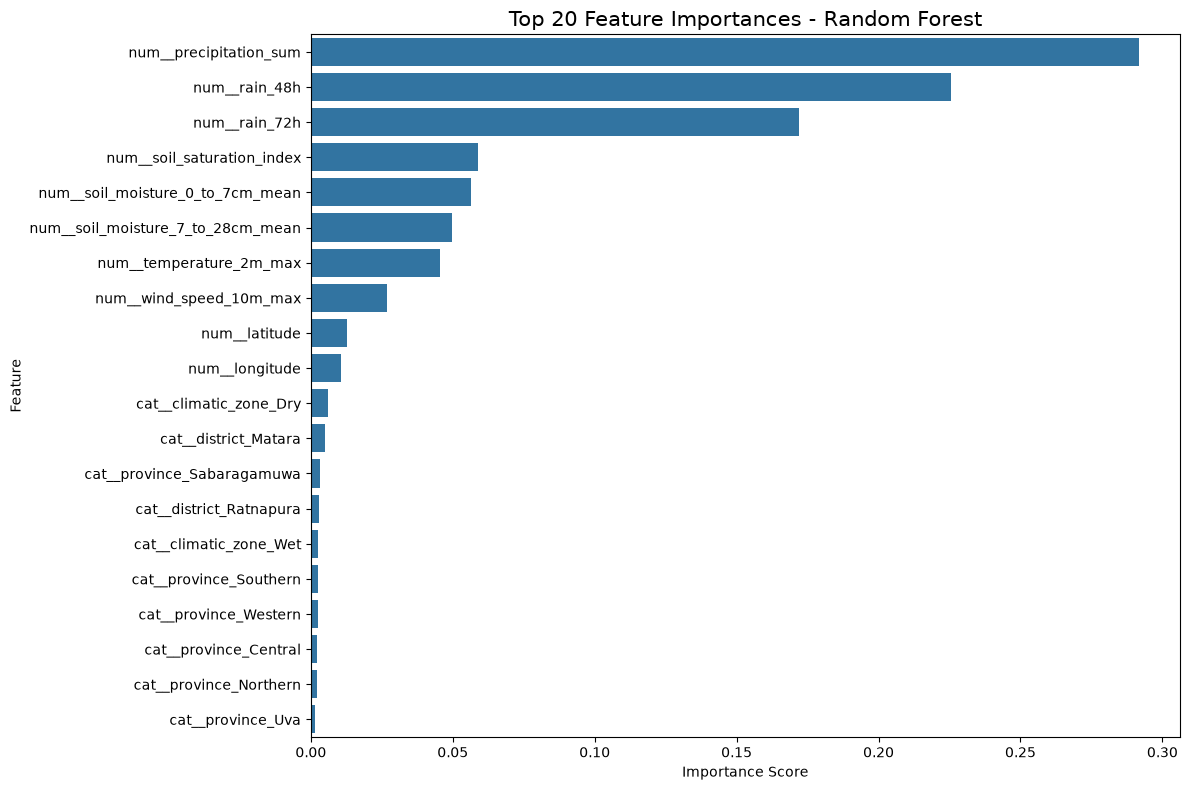

In [67]:
plt.figure(figsize=(12, 8))

top_rf_features = rf_feature_importance.head(20)

sns.barplot(
    data=top_rf_features,
    x='Importance',
    y='Feature'
)

plt.title(
    'Top 20 Feature Importances - Random Forest',
    fontsize=15
)

plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [68]:
xgb_importance = xgb_model.feature_importances_

xgb_feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_importance
})

xgb_feature_importance = xgb_feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(xgb_feature_importance.head(20))

,Feature,Importance
0,num__precipitation_sum,0.161667
7,num__rain_48h,0.137658
23,cat__district_Kurunegala,0.078404
27,cat__district_Monaragala,0.075204
35,cat__province_Central,0.038229
36,cat__province_Eastern,0.037048
5,num__latitude,0.035538
16,cat__district_Gampaha,0.032429
8,num__rain_72h,0.029021
44,cat__climatic_zone_Dry,0.028863


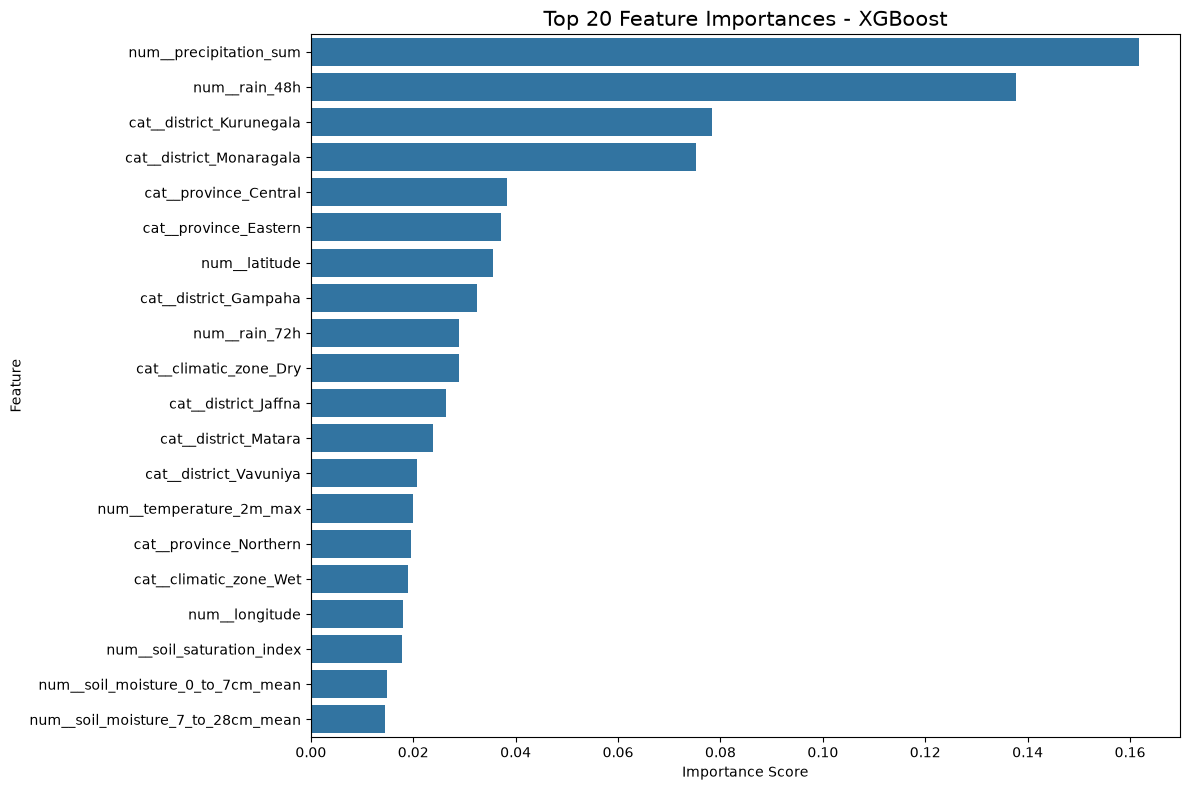

In [69]:
plt.figure(figsize=(12, 8))

top_xgb_features = xgb_feature_importance.head(20)

sns.barplot(
    data=top_xgb_features,
    x='Importance',
    y='Feature'
)

plt.title(
    'Top 20 Feature Importances - XGBoost',
    fontsize=15
)

plt.xlabel('Importance Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [70]:
# Combine both feature importance results
importance_comparison = pd.merge(
    rf_feature_importance,
    xgb_feature_importance,
    on='Feature',
    suffixes=('_RF', '_XGBoost')
)

importance_comparison = importance_comparison.sort_values(
    by='Importance_XGBoost',
    ascending=False
)

display(importance_comparison.head(20))

,Feature,Importance_RF,Importance_XGBoost
0,num__precipitation_sum,0.291617,0.161667
1,num__rain_48h,0.225457,0.137658
21,cat__district_Kurunegala,0.001246,0.078404
22,cat__district_Monaragala,0.001196,0.075204
17,cat__province_Central,0.002131,0.038229
23,cat__province_Eastern,0.001184,0.037048
8,num__latitude,0.012876,0.035538
32,cat__district_Gampaha,0.000755,0.032429
2,num__rain_72h,0.171909,0.029021
10,cat__climatic_zone_Dry,0.005942,0.028863


In [73]:
from sklearn.inspection import permutation_importance

# Select a sample from the testing dataset
sample_size = min(3000, X_test_processed.shape[0])

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    X_test_processed.shape[0],
    size=sample_size,
    replace=False
)

# Convert sparse matrix into dense NumPy array
X_perm = X_test_processed[sample_indices].toarray()

y_perm = y_test_encoded[sample_indices]

print("Permutation Dataset Shape:", X_perm.shape)

# Calculate permutation importance
perm_result = permutation_importance(
    xgb_model,
    X_perm,
    y_perm,
    scoring='f1_macro',
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Create results dataframe
permutation_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

display(permutation_df.head(20))

Permutation Dataset Shape: (3000, 47)


,Feature,Importance,Std
0,num__precipitation_sum,0.105942,0.002826
9,num__soil_saturation_index,0.042343,0.001083
8,num__rain_72h,0.005968,0.001048
2,num__soil_moisture_7_to_28cm_mean,0.004195,0.000842
1,num__soil_moisture_0_to_7cm_mean,0.001168,0.000622
6,num__longitude,0.000167,0.000237
4,num__wind_speed_10m_max,0.000000,0.000000
13,cat__district_Batticaloa,0.000000,0.000000
5,num__latitude,0.000000,0.000000
10,cat__district_Ampara,0.000000,0.000000


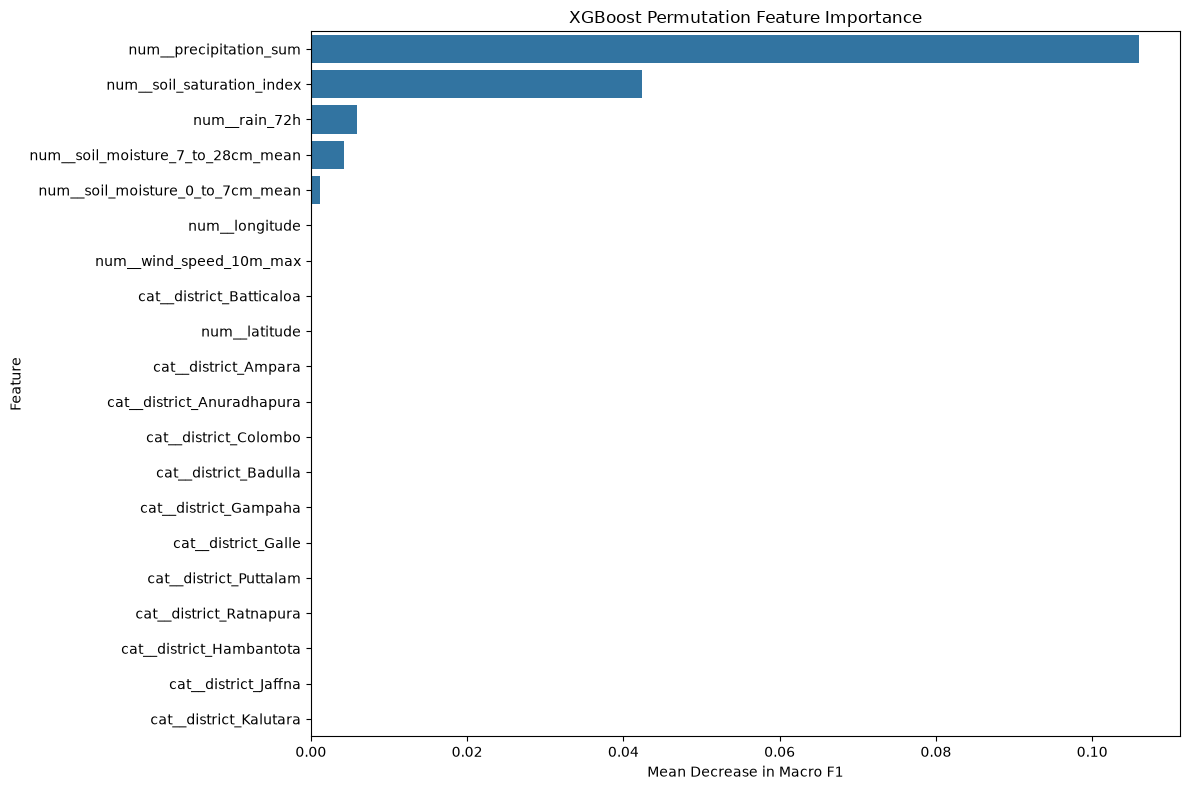

In [74]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=permutation_df.head(20),
    x='Importance',
    y='Feature'
)

plt.title('XGBoost Permutation Feature Importance')
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [75]:
# Select best model based on Macro F1
best_model_name = final_comparison_df.iloc[0]['Model']

model_dictionary = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Extra Trees': et_model,
    'XGBoost': xgb_model,
    'Stacking Classifier': stacking_model
}

best_model = model_dictionary[best_model_name]

print("Selected Model:", best_model_name)
print("Selection Metric: Macro F1")

print(
    "Macro F1:",
    round(final_comparison_df.iloc[0]['Macro F1'], 4)
)

Selected Model: XGBoost
Selection Metric: Macro F1
Macro F1: 0.8382


In [76]:
# Save feature importance
rf_feature_importance.to_csv(
    '../models/random_forest_feature_importance.csv',
    index=False
)

xgb_feature_importance.to_csv(
    '../models/xgboost_feature_importance.csv',
    index=False
)

permutation_df.to_csv(
    '../models/permutation_feature_importance.csv',
    index=False
)

print("Feature importance results saved successfully!")

Feature importance results saved successfully!
